In [1]:
!pip install catboost xgboost lightgbm gradio

# Task 07 — Apartments Prices (Regression)
**Goal:** predict the price (EGP) of an apartment. **Target:** `price` (we train on `log(price)` because prices are skewed). **Features:** area, rooms, bathrooms, floor, year built, seller type, view, payment method, finishing type (`price_per_sqm` is not used: it is computed from the price = leakage).

**Metrics:** MAE, MSE, RMSE and R². Errors are reported on the log scale and in real EGP.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. Load the data

In [3]:
import os
path = 'dataset/Apartments_Prices_Dataset.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'Apartments_Prices_Dataset.csv'
df = pd.read_csv(path)
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [4]:
df.shape

(5578, 11)

In [5]:
df.columns

Index(['price', 'area_sqm', 'rooms', 'bathrooms', 'floor_level', 'year_built',
       'seller_type', 'view', 'price_per_sqm', 'payment_method',
       'finishing_type'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5578 non-null   object
 1   area_sqm        5578 non-null   object
 2   rooms           5578 non-null   object
 3   bathrooms       5578 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5578 non-null   object
 7   view            5578 non-null   object
 8   price_per_sqm   5578 non-null   object
 9   payment_method  5578 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB


In [7]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


## 2. Data cleaning

In [8]:
df.isnull().sum()

,0
price,0
area_sqm,0
rooms,0
bathrooms,0
floor_level,0
year_built,0
seller_type,0
view,0
price_per_sqm,0
payment_method,0


In [9]:
df.duplicated().sum()

np.int64(1489)

In [10]:
df = df.drop_duplicates()

In [11]:
df.shape

(4089, 11)

**Text to numbers:** price, area, rooms, bathrooms and floor are text (`'2,163,000 EGP'`, `'120 m²'`, `'3 rooms'`...). The units are removed and the columns become numbers.

In [12]:
df["price"] = df["price"].str.replace(r"\D", "", regex=True).astype(float)
df["area_sqm"] = df["area_sqm"].str.replace(r"\D", "", regex=True).astype(float)
df["rooms"] = df["rooms"].str.extract(r"(\d+)")[0].astype(float)
df["bathrooms"] = df["bathrooms"].str.extract(r"(\d+)")[0].astype(float)
df["floor_level"] = df["floor_level"].replace("Ground", "0").astype(float)

In [13]:
df["seller_type"].value_counts()

,count
seller_type,
Broker,3539
Developer,335
Private Owner,164
Compound Developer,21
Cash,19
Cash or Installments,6
Installments,5


**Shifted columns:** in some rows the value of `seller_type` is a payment method (the columns are shifted), so the right value is recovered from `price_per_sqm`.

In [14]:
shifted = df["seller_type"].isin(["Cash", "Installments", "Cash or Installments"])
shifted.sum()

np.int64(30)

In [15]:
df.loc[shifted, "seller_type"] = df.loc[shifted, "price_per_sqm"]

In [16]:
df["seller_type"].value_counts()

,count
seller_type,
Broker,3555
Developer,341
Private Owner,172
Compound Developer,21


**Impossible values:** the price per m² is calculated only to remove listings with an absurd price/area; then `price_per_sqm` and `ppsqm` are dropped (they are made from the target = leakage). Impossible values (230 rooms, area of 5 m², year 2037...) are set to missing and filled after the split.

In [17]:
df["ppsqm"] = df["price"] / df["area_sqm"]
df["ppsqm"].describe()

,ppsqm
count,4089.000000
mean,42754.864121
std,28098.092667
min,4166.666667
25%,25000.000000
50%,36786.474684
75%,53906.250000
max,655172.413793


In [18]:
df = df[(df["ppsqm"] >= 5000) & (df["ppsqm"] <= 200000)]

In [19]:
df = df.drop(columns=["price_per_sqm", "ppsqm"])

In [20]:
df.loc[df["rooms"] > 6, "rooms"] = np.nan
df.loc[df["bathrooms"] > 6, "bathrooms"] = np.nan
df.loc[df["floor_level"] > 30, "floor_level"] = np.nan
df.loc[(df["area_sqm"] < 30) | (df["area_sqm"] > 600), "area_sqm"] = np.nan
df.loc[(df["year_built"] < 1960) | (df["year_built"] > 2030), "year_built"] = np.nan

In [21]:
df.isnull().sum()

,0
price,0
area_sqm,1
rooms,6
bathrooms,4
floor_level,2
year_built,6
seller_type,0
view,0
payment_method,0
finishing_type,0


In [22]:
df.shape

(4083, 10)

### Outliers (IQR rule)

In [23]:
for col in ['price', 'area_sqm', 'rooms', 'bathrooms', 'floor_level']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / df[col].notna().sum() * 100:.1f}%)  [valid range {low:.0f} to {high:.0f}]  max = {df[col].max():.0f}")

price: 191 outliers (4.7%)  [valid range -2800000 to 14000000]  max = 51000000
area_sqm: 101 outliers (2.5%)  [valid range 28 to 272]  max = 534
rooms: 20 outliers (0.5%)  [valid range 0 to 4]  max = 5
bathrooms: 0 outliers (0.0%)  [valid range -2 to 6]  max = 6
floor_level: 225 outliers (5.5%)  [valid range -4 to 8]  max = 22


**Decision:** the clearly impossible values were already removed or set to missing in the cleaning step. The remaining IQR outliers (big luxury apartments, very high prices) are real, so they are **kept**; the skew is handled with `log1p` on the target and on the skewed features, and the models are scaled.

## 3. EDA (visualization)

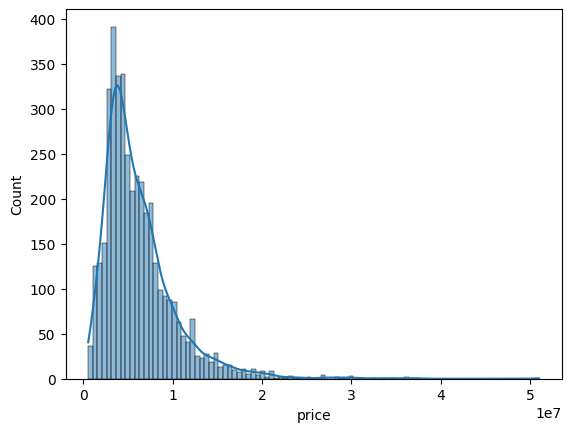

In [24]:
sns.histplot(df["price"], kde=True)
plt.show()

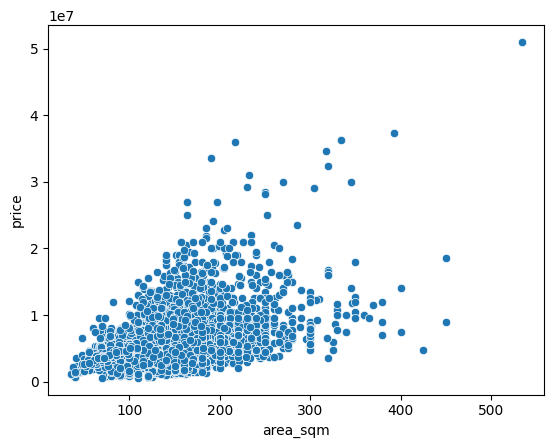

In [25]:
sns.scatterplot(x="area_sqm", y="price", data=df)
plt.show()

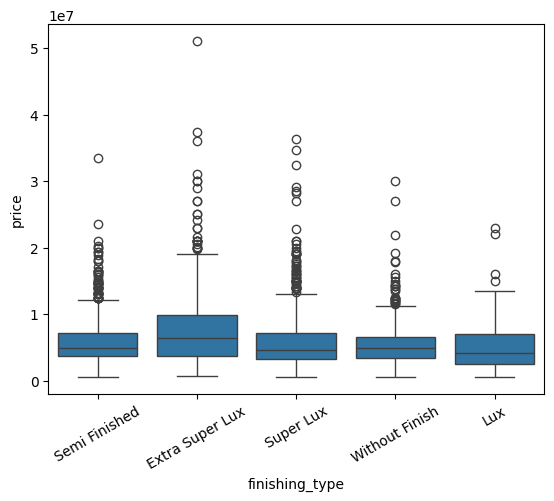

In [26]:
sns.boxplot(x="finishing_type", y="price", data=df)
plt.xticks(rotation=30)
plt.show()

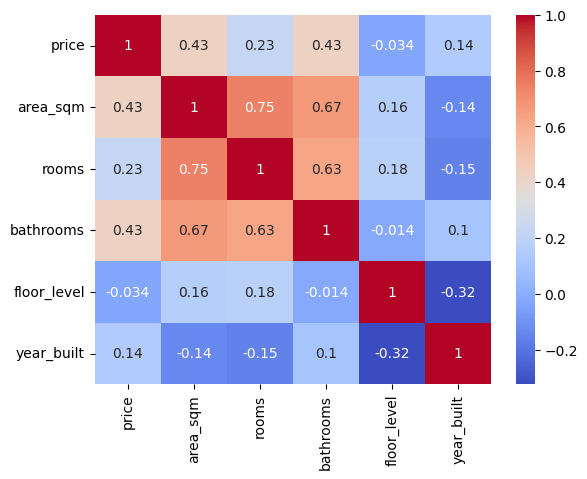

In [27]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

## 4. Encoding
Finishing type is ordinal (0-4); seller type, view and payment method are one-hot encoded.

In [28]:
finishing = {"Without Finish": 0, "Semi Finished": 1, "Lux": 2, "Super Lux": 3, "Extra Super Lux": 4}
df["finishing_type"] = df["finishing_type"].map(finishing)

In [29]:
df_clean = df.copy()

In [30]:
onehot_cols = ["seller_type", "view", "payment_method"]
df = pd.get_dummies(df, columns=onehot_cols, drop_first=True, dtype=int)

In [31]:
X = df.drop(columns="price")

In [32]:
y = np.log1p(df["price"])

## 5. Train / Test split

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Fill missing values (median of the train data only, then applied to test) -> no data leakage

In [34]:
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

In [35]:
X_train.isnull().sum().sum()

np.int64(0)

## 6. Skewed features and scaling (fit on train only)

In [36]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]

In [37]:
skewed = [c for c in num_cols if abs(X_train[c].skew()) > 0.75]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed] = np.log1p(X_test[skewed])

In [38]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

## 7. All the models
All models of the track are trained on the log target and evaluated on the test set (errors on the log scale).

In [39]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [40]:
from sklearn.linear_model import ElasticNet
models["ElasticNet"] = ElasticNet()

In [41]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/16 [00:00<?, ?it/s]

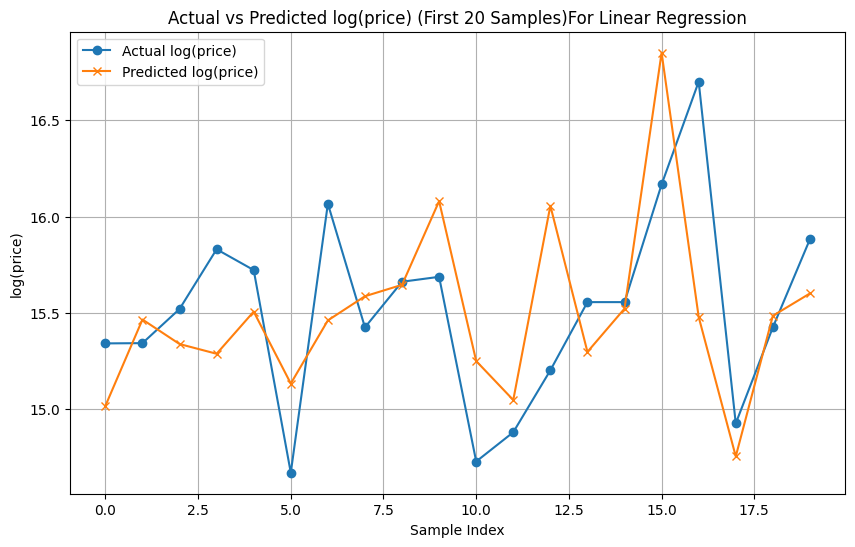

  6%|▋         | 1/16 [00:00<00:09,  1.55it/s]

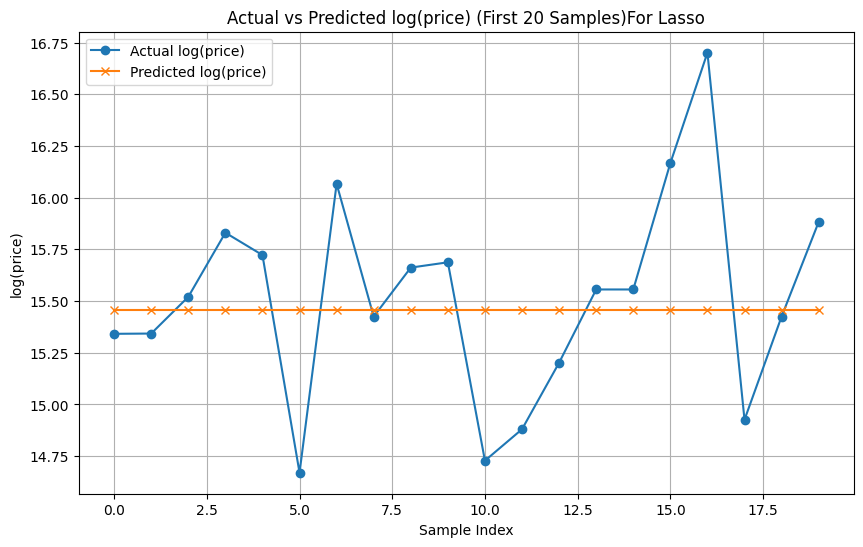

 12%|█▎        | 2/16 [00:01<00:09,  1.54it/s]

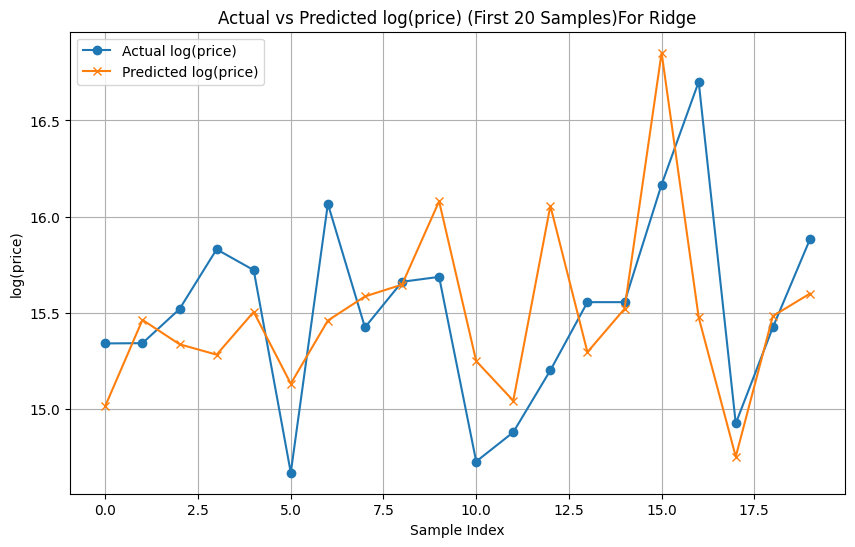

 19%|█▉        | 3/16 [00:02<00:10,  1.23it/s]

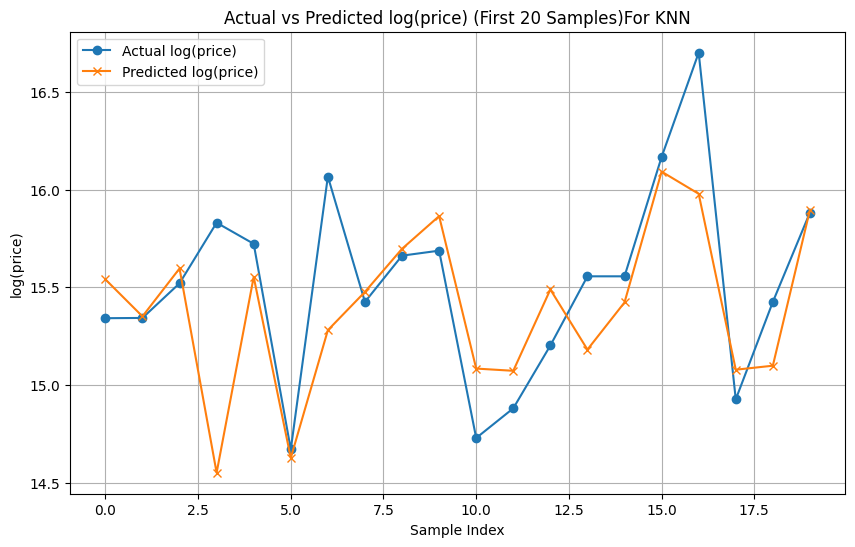

 25%|██▌       | 4/16 [00:04<00:15,  1.26s/it]

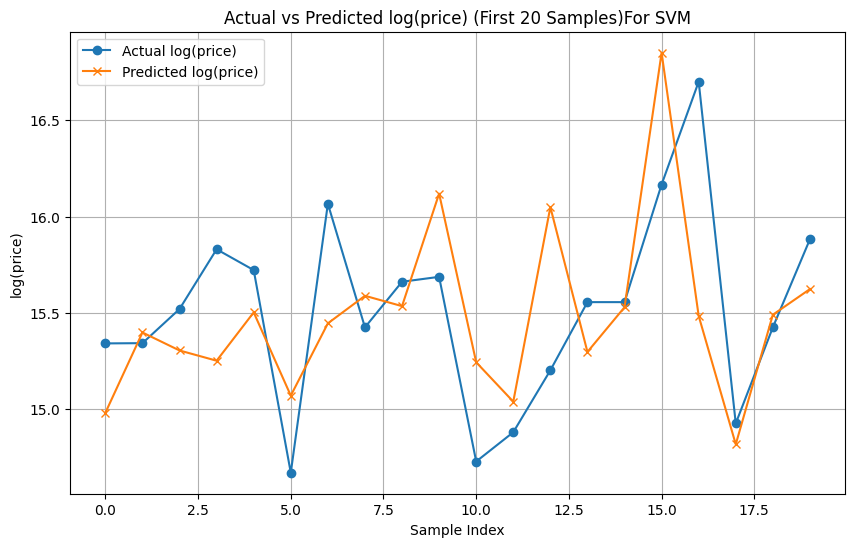

 31%|███▏      | 5/16 [00:09<00:30,  2.81s/it]

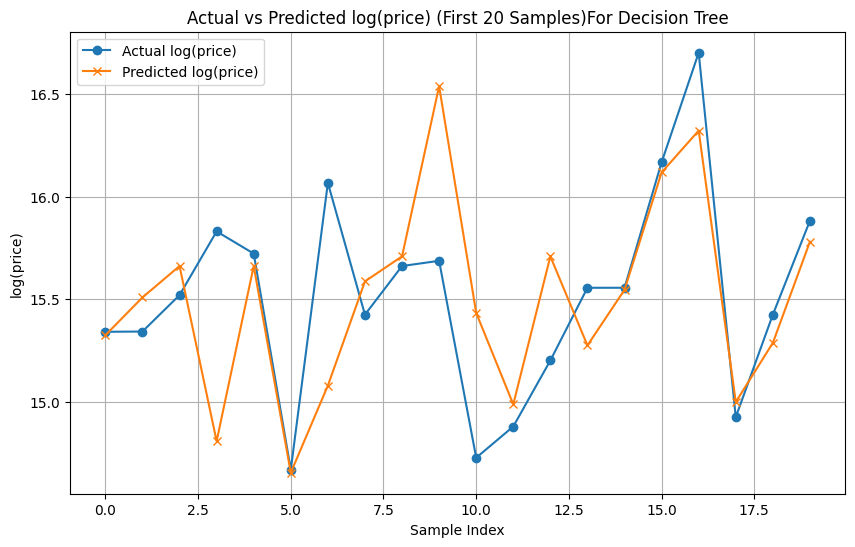

 38%|███▊      | 6/16 [00:10<00:20,  2.01s/it]

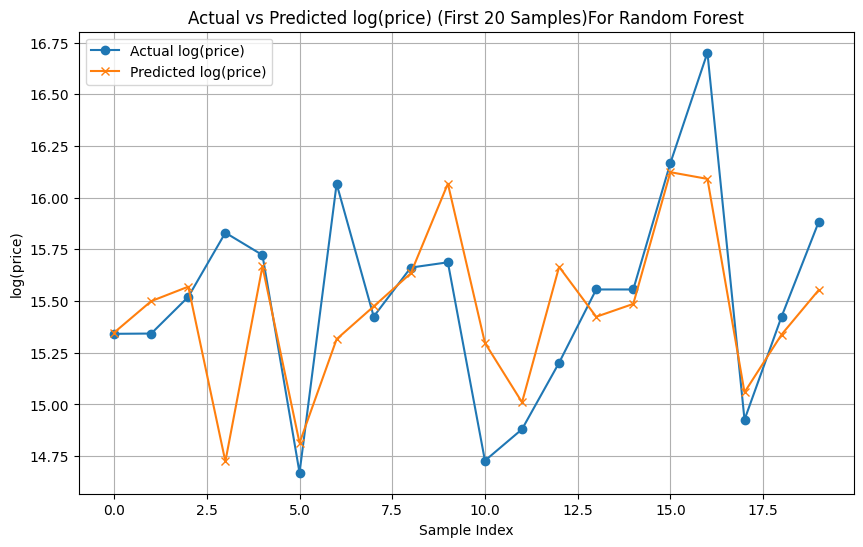

 44%|████▍     | 7/16 [00:11<00:17,  1.90s/it]

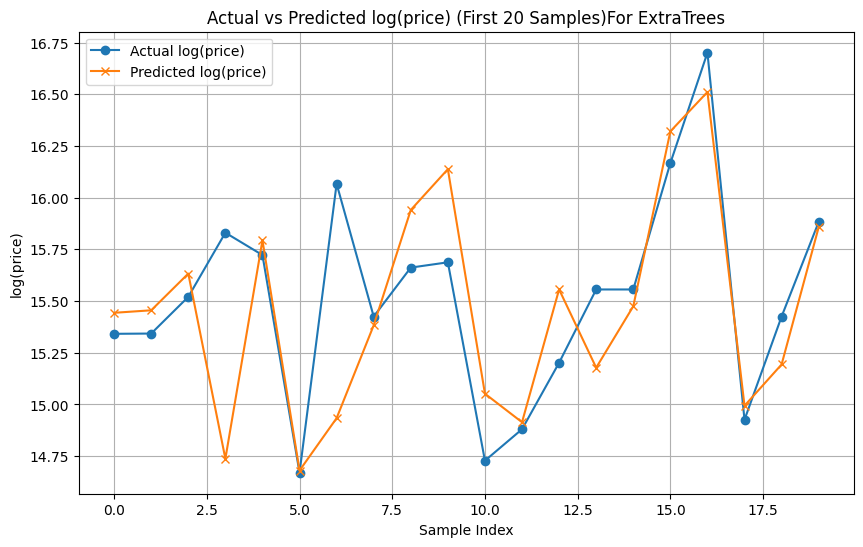

 50%|█████     | 8/16 [00:15<00:19,  2.38s/it]

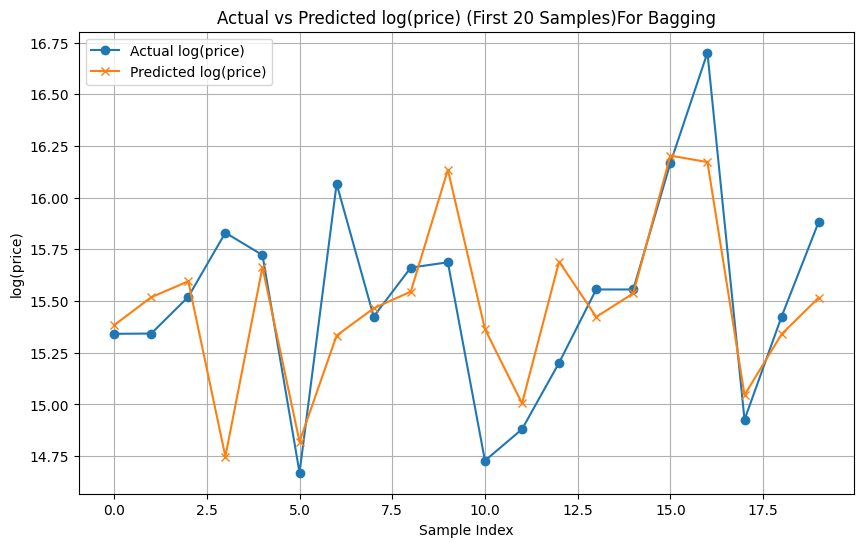

 56%|█████▋    | 9/16 [00:17<00:15,  2.17s/it]

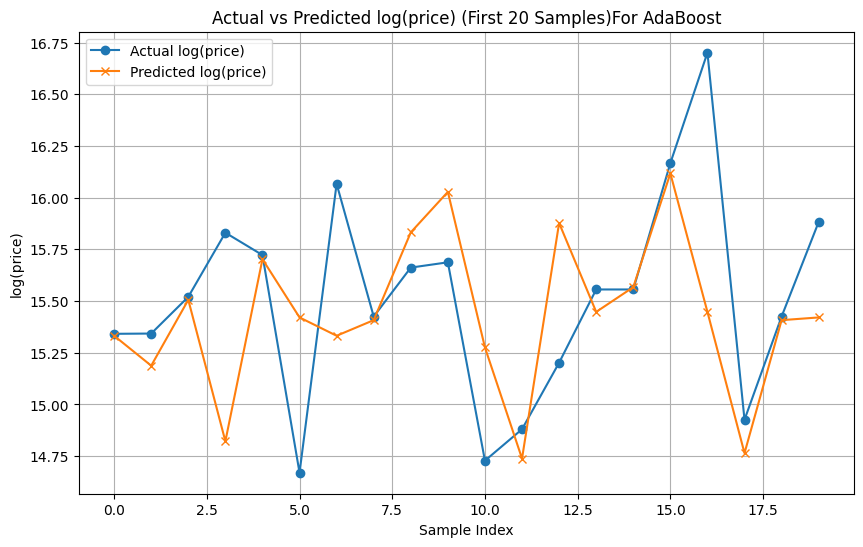

 62%|██████▎   | 10/16 [00:17<00:10,  1.76s/it]

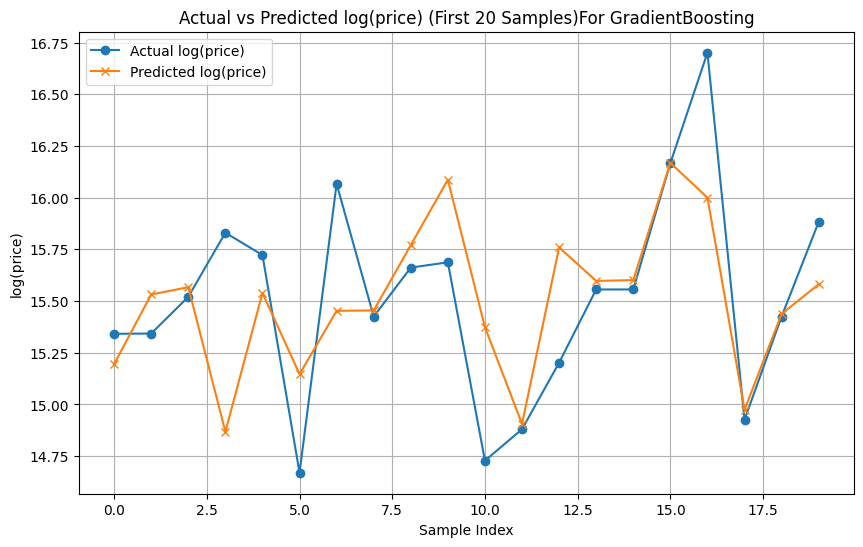

 69%|██████▉   | 11/16 [00:19<00:08,  1.79s/it]

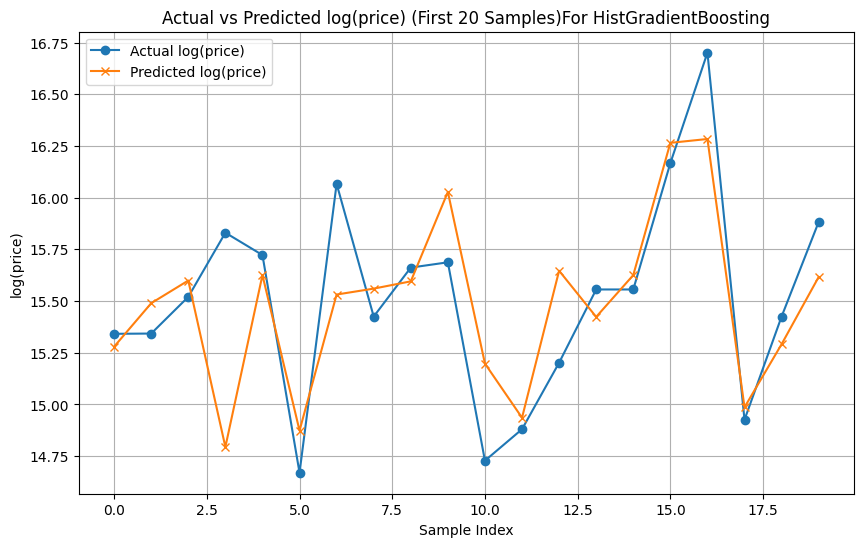

 75%|███████▌  | 12/16 [00:22<00:07,  1.95s/it]

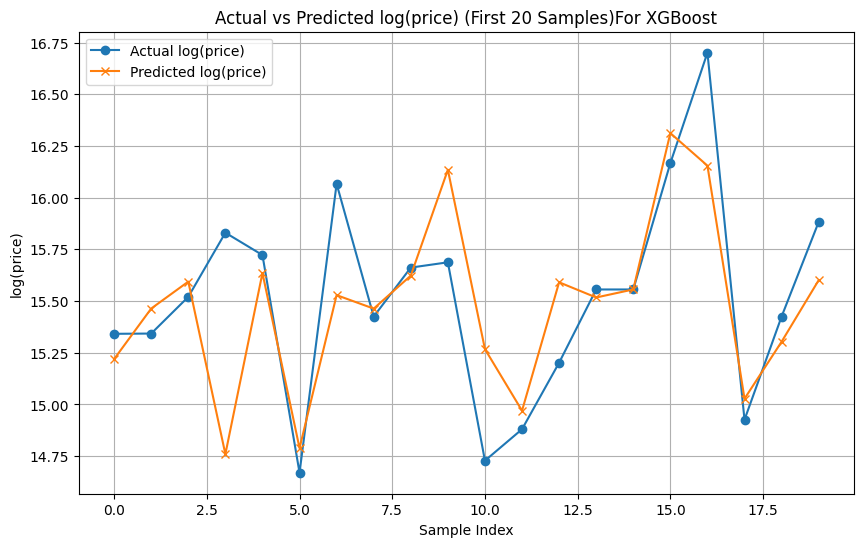

 81%|████████▏ | 13/16 [00:23<00:05,  1.83s/it]

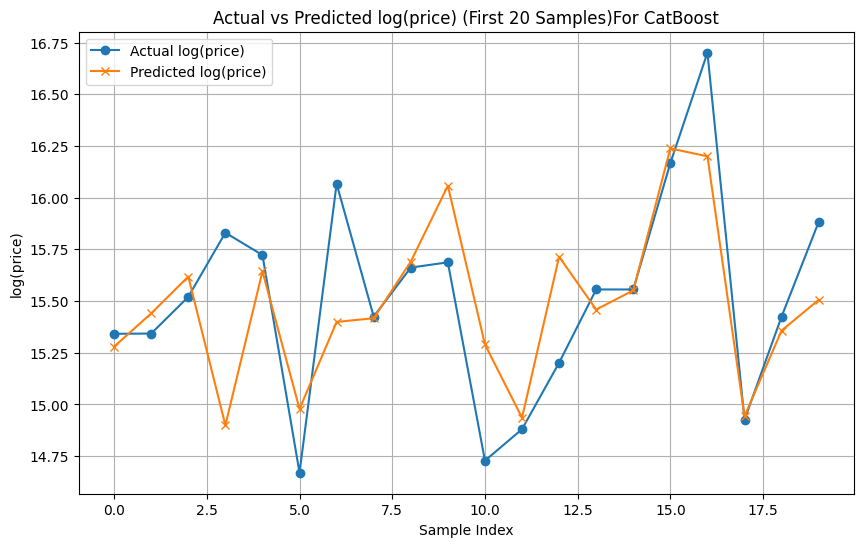

 88%|████████▊ | 14/16 [00:24<00:02,  1.49s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007841 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 310
[LightGBM] [Info] Number of data points in the train set: 3266, number of used features: 19
[LightGBM] [Info] Start training from score 15.455143


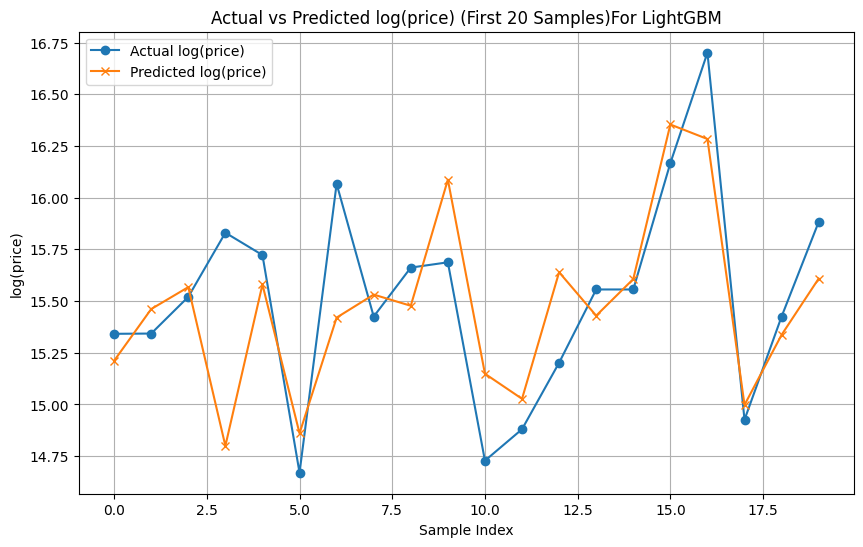

 94%|█████████▍| 15/16 [00:25<00:01,  1.26s/it]

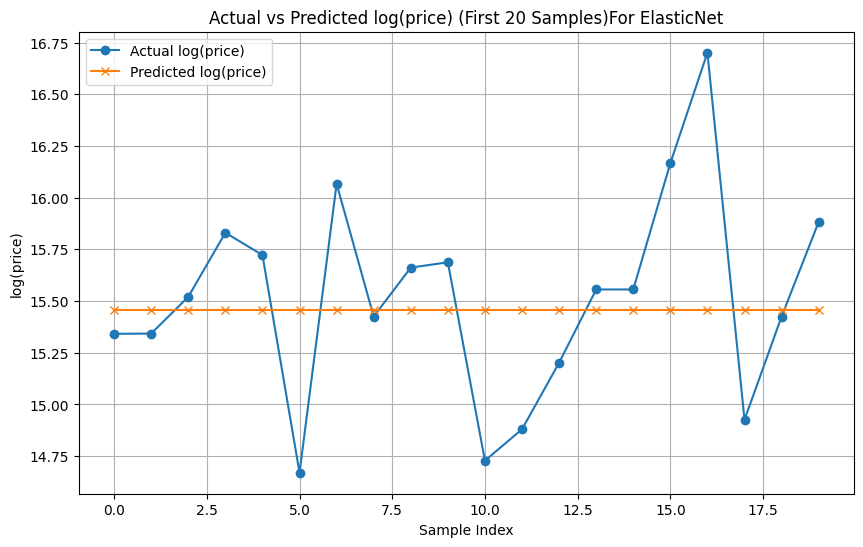

100%|██████████| 16/16 [00:25<00:00,  1.60s/it]


In [42]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual log(price)', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted log(price)', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('log(price)')
    plt.title('Actual vs Predicted log(price) (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [43]:
# Voting regressors (averaging). The old 'Simple Voting' was identical to 'Voting', so it is kept once.
def add_errors(name, model):
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model, X_test, y_test)
    errors[name] = {
        "MAE Train": MAE_Train, "MAE Test": MAE_Test,
        "MSE Train": MSE_Train, "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train, "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train, "R2 Test": R2_Test
    }

clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

model1 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)])
model3 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], weights=[2, 1, 2])

model1.fit(X_train, y_train)
model3.fit(X_train, y_train)

add_errors("Voting", model1)
add_errors("Weighted Voting", model3)

In [44]:
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=XGBRegressor(),
    cv=5,
    passthrough=True,
    n_jobs=-1
)

stacking_regressor.fit(X_train, y_train)
add_errors("Stacking", stacking_regressor)

In [45]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [46]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,0.210041,0.268440,0.079969,0.123811,0.282788,0.351868,0.785737,0.665375
HistGradientBoosting,0.221896,0.271524,0.085697,0.126270,0.292740,0.355345,0.770390,0.658729
LightGBM,0.223379,0.270740,0.087081,0.126835,0.295095,0.356139,0.766681,0.657203
Random Forest,0.216778,0.278472,0.081113,0.132637,0.284803,0.364194,0.782672,0.641520
Bagging,0.219545,0.278338,0.082820,0.132738,0.287784,0.364333,0.778098,0.641248
CatBoost,0.277983,0.286486,0.129840,0.135649,0.360333,0.368305,0.652116,0.633381
Stacking,0.198838,0.281850,0.081802,0.139428,0.286011,0.373401,0.780825,0.623166
Voting,0.148010,0.287455,0.036331,0.143429,0.190608,0.378721,0.902656,0.612353
ExtraTrees,0.008051,0.272891,0.001935,0.145678,0.043986,0.381678,0.994816,0.606276
GradientBoosting,0.293293,0.297899,0.142589,0.146211,0.377609,0.382376,0.617958,0.604834


<Axes: >

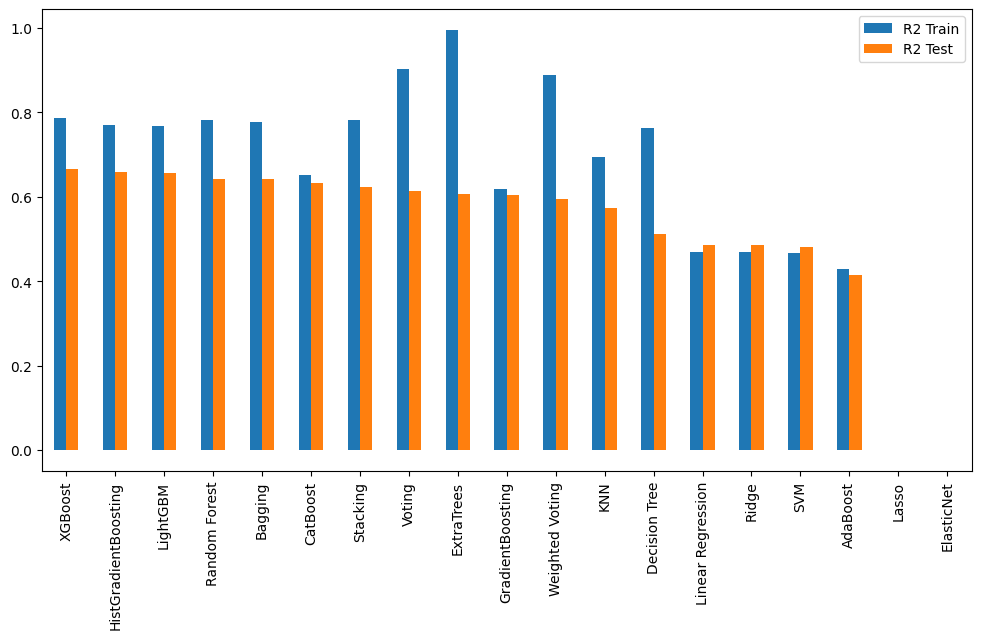

In [47]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

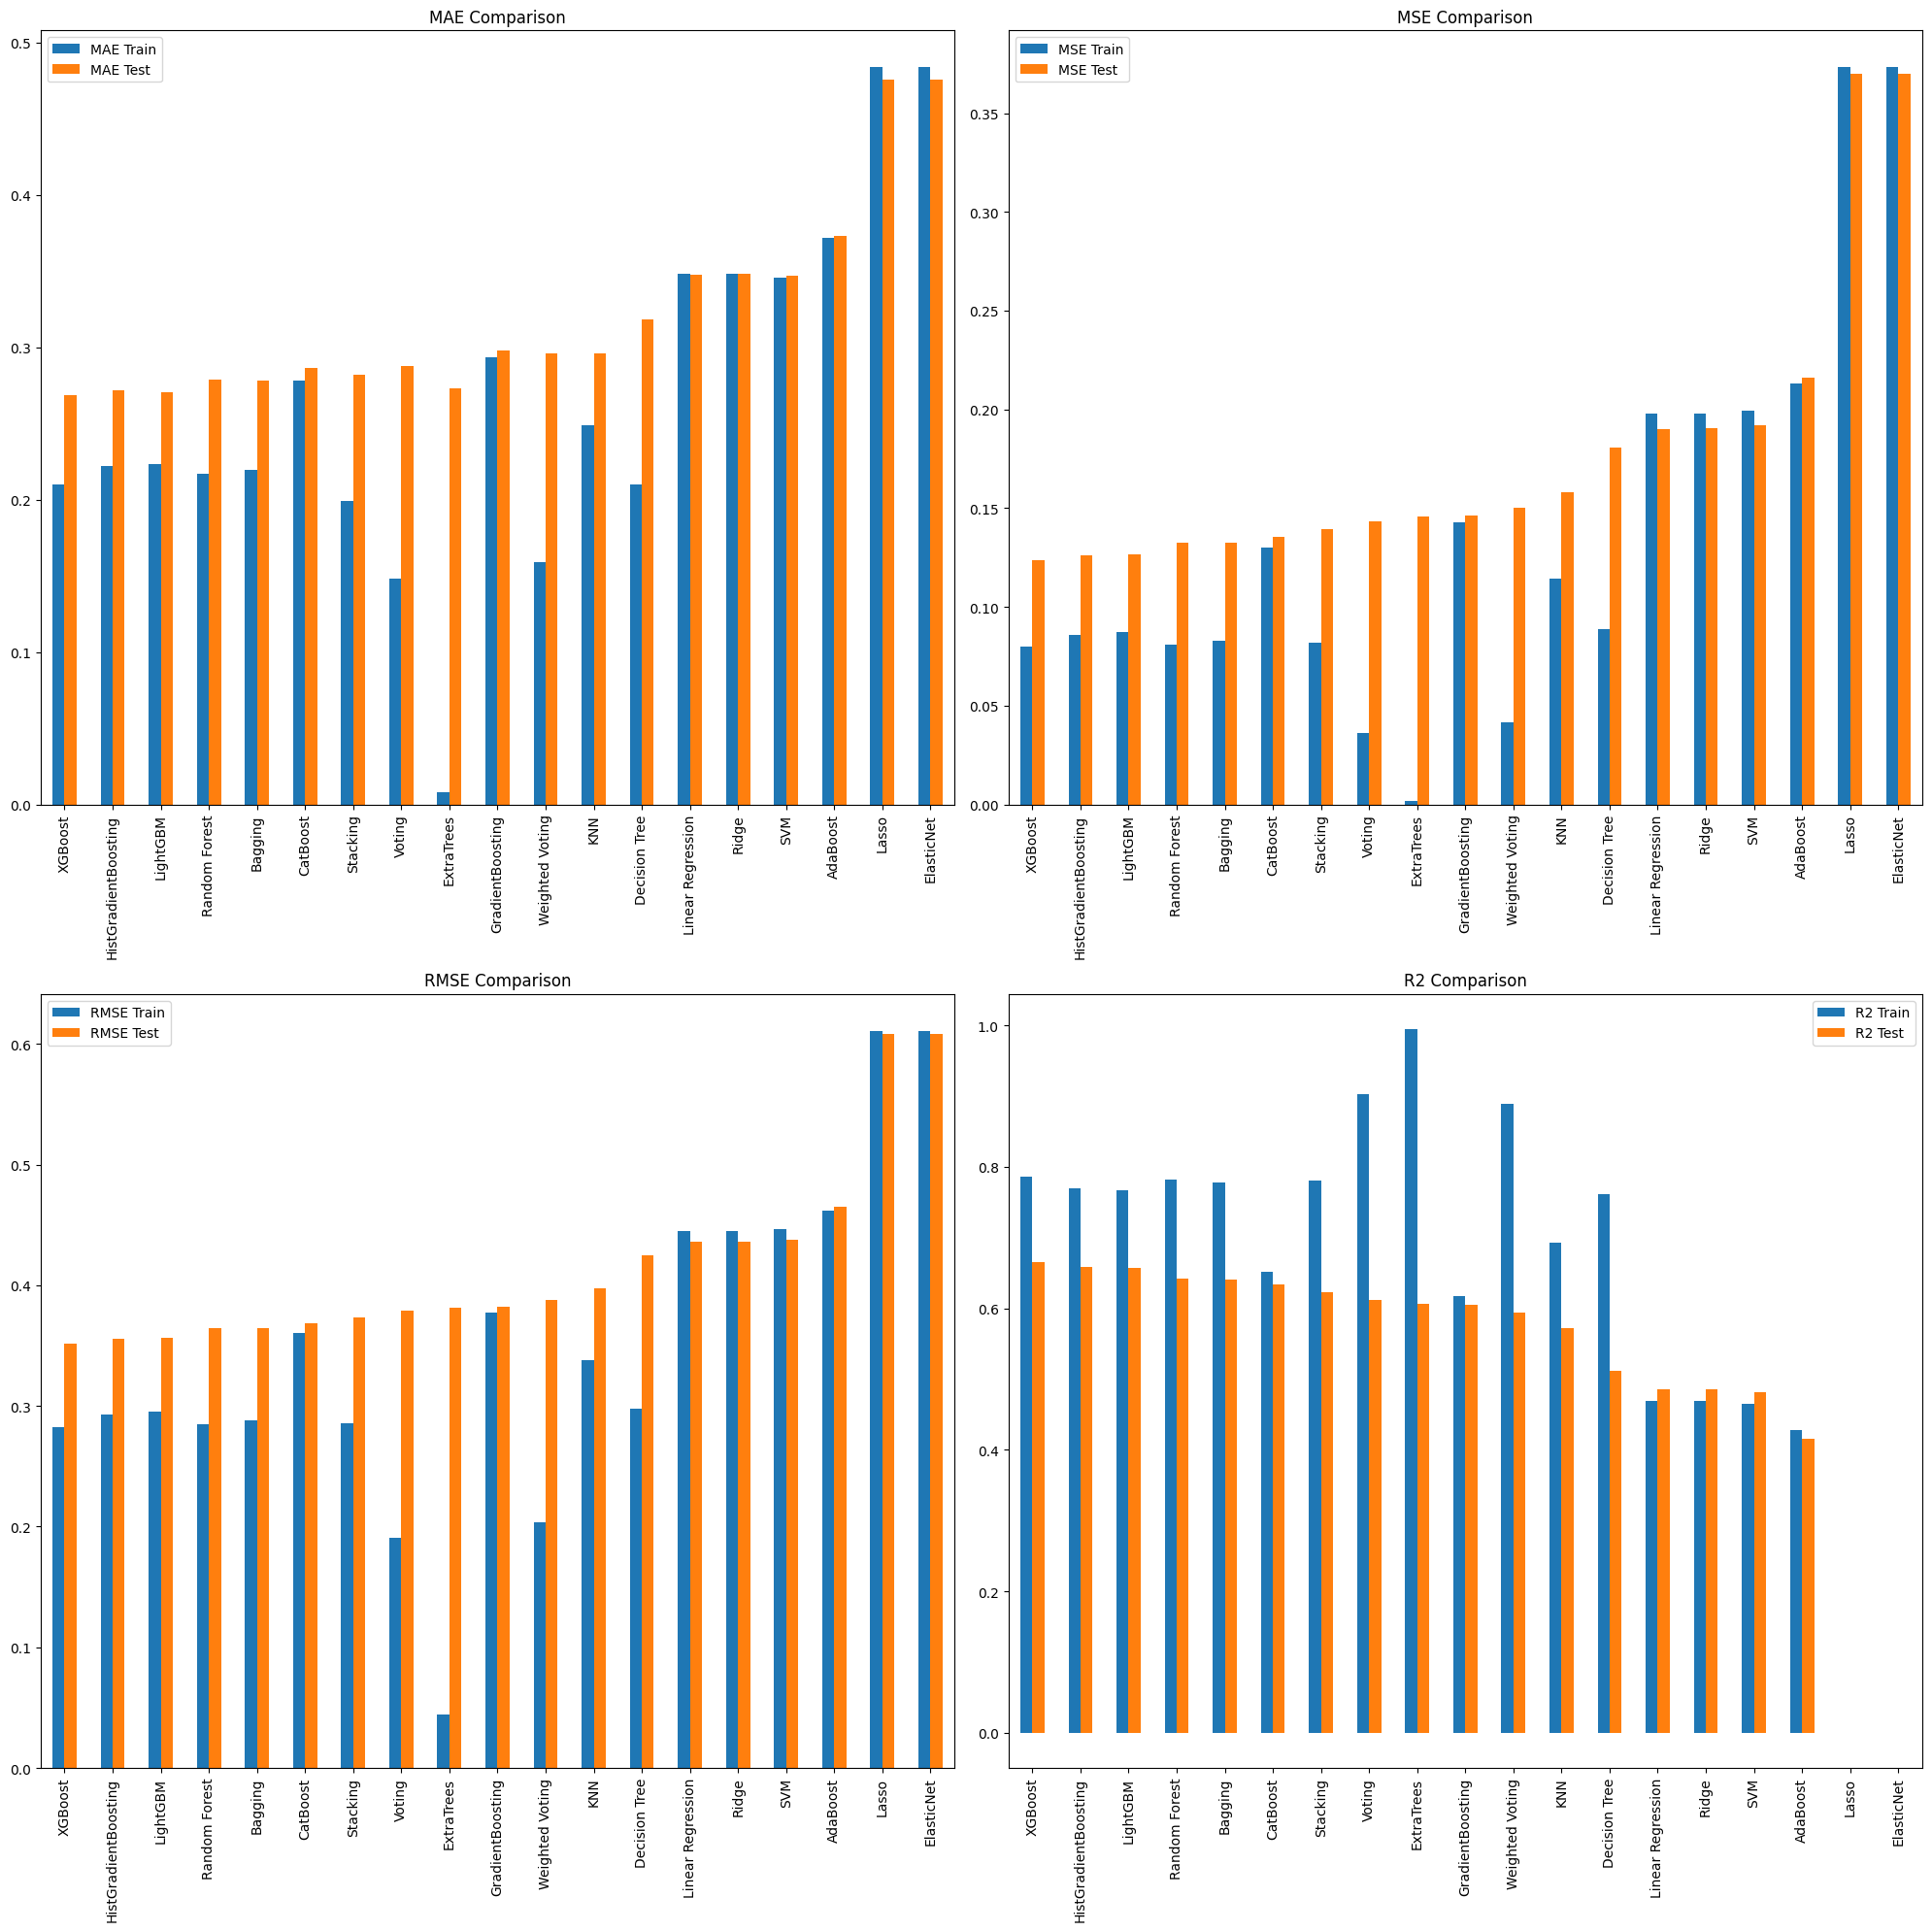

In [48]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** the table above uses the test set to show how each model behaves (errors are on the **log(price)** scale). To **choose** and **tune** the final model we do not use the test set: we use cross-validation on the training data (next sections). Large gaps between Train and Test R² mean overfitting (e.g. Decision Tree, ExtraTrees, Random Forest).

## 9. Model comparison with Cross-Validation (train data only)
5-fold cross-validation on the training data, metric **R²** (and RMSE on log(price)).

In [49]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.base import clone

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, model in tqdm(models.items()):
    cv = cross_validate(clone(model), X_train, y_train, cv=kf, n_jobs=-1,
                        scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'})
    cv_rows[name] = {'CV R2': cv['test_r2'].mean(), 'CV RMSE (log)': -cv['test_rmse'].mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values('CV R2', ascending=False)
cv_df

100%|██████████| 16/16 [00:22<00:00,  1.38s/it]


,CV R2,CV RMSE (log)
LightGBM,0.604848,0.382873
HistGradientBoosting,0.604145,0.383205
XGBoost,0.595992,0.387316
Random Forest,0.587423,0.391423
Bagging,0.584233,0.392884
CatBoost,0.582974,0.393326
GradientBoosting,0.551769,0.407640
ExtraTrees,0.549327,0.408464
KNN,0.524398,0.420113
Linear Regression,0.459250,0.447659


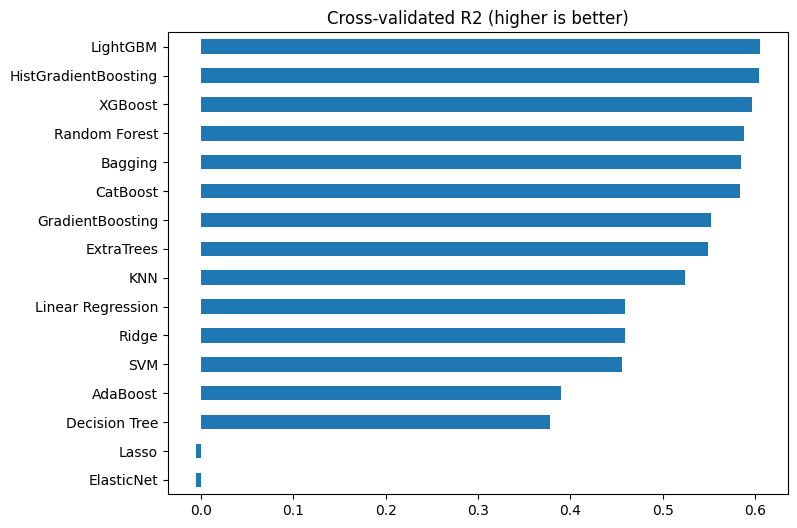

In [50]:
cv_df['CV R2'].sort_values().plot.barh(figsize=(8, 6))
plt.title('Cross-validated R2 (higher is better)')
plt.show()

## 10. GridSearchCV on the best 3 models
The top 3 models of the cross-validation comparison are tuned with `GridSearchCV` (5-fold, metric R², training data only).

In [51]:
param_grids = {
    'Linear Regression': {'fit_intercept': [True, False]},
    'Lasso': {'alpha': [0.0001, 0.0005, 0.001, 0.01]},
    'Ridge': {'alpha': [1, 3, 10, 30, 100]},
    'ElasticNet': {'alpha': [0.0005, 0.001, 0.01], 'l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'n_neighbors': [3, 5, 9, 15], 'weights': ['uniform', 'distance']},
    'SVM': {'C': [0.1, 1], 'epsilon': [0.01, 0.1]},
    'Decision Tree': {'max_depth': [4, 6, 10], 'min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'n_estimators': [100, 300], 'max_depth': [10, None], 'min_samples_leaf': [1, 3]},
    'ExtraTrees': {'n_estimators': [100, 300], 'max_depth': [10, None], 'min_samples_leaf': [1, 3]},
    'Bagging': {'n_estimators': [50, 100], 'max_samples': [0.7, 1.0]},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.05, 0.1, 0.5]},
    'GradientBoosting': {'n_estimators': [200, 500], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 3]},
    'HistGradientBoosting': {'max_iter': [200, 400], 'learning_rate': [0.03, 0.1], 'max_depth': [None, 4]},
    'XGBoost': {'n_estimators': [300, 600], 'max_depth': [2, 3], 'learning_rate': [0.03, 0.1]},
    'CatBoost': {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    'LightGBM': {'n_estimators': [300, 600], 'num_leaves': [8, 15], 'learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    grid = GridSearchCV(clone(models[name]), param_grids[name], cv=kf, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV R2'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV R2)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['LightGBM', 'HistGradientBoosting', 'XGBoost']
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000115 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 310
[LightGBM] [Info] Number of data points in the train set: 3266, number of used features: 19
[LightGBM] [Info] Start training from score 15.455143

LightGBM
  best_params_: {'learning_rate': 0.03, 'n_estimators': 600, 'num_leaves': 15}
  best_score_ : 0.6055

HistGradientBoosting
  best_params_: {'learning_rate': 0.03, 'max_depth': None, 'max_iter': 400}
  best_score_ : 0.6058

XGBoost
  best_params_: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 600}
  best_score_ : 0.5801


,Before tuning (CV R2),After tuning (best_score_)
Model,,
LightGBM,0.604848,0.605451
HistGradientBoosting,0.604145,0.605759
XGBoost,0.595992,0.580145


**Why these parameters:** `alpha` is the regularization strength of the linear models; depth / leaf size control overfitting of the trees; `learning_rate` and the number of trees trade off in boosting; `n_neighbors` controls the smoothness of KNN. The grids are small on purpose to keep the search fast.

## 11. Final model and evaluation on the test set (used once)

In [52]:
best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = tuned[best_name].best_estimator_          # already refitted on the whole train data
print("Best model:", best_name, tuned[best_name].best_params_)

pred_log = best_model.predict(X_test)
pred_real = np.expm1(pred_log)
y_real = np.expm1(y_test)          # real prices of the test rows

results = pd.DataFrame({
    'log(price)': [mean_absolute_error(y_test, pred_log), mean_squared_error(y_test, pred_log),
                       np.sqrt(mean_squared_error(y_test, pred_log)), r2_score(y_test, pred_log)],
    'Real price (EGP)': [mean_absolute_error(y_real, pred_real), mean_squared_error(y_real, pred_real),
                       np.sqrt(mean_squared_error(y_real, pred_real)), r2_score(y_real, pred_real)],
}, index=['MAE', 'MSE', 'RMSE', 'R2'])
results

Best model: HistGradientBoosting {'learning_rate': 0.03, 'max_depth': None, 'max_iter': 400}


,log(price),Real price (EGP)
MAE,0.268820,1.726507e+06
MSE,0.124775,8.626438e+12
RMSE,0.353235,2.937080e+06
R2,0.662771,5.100832e-01


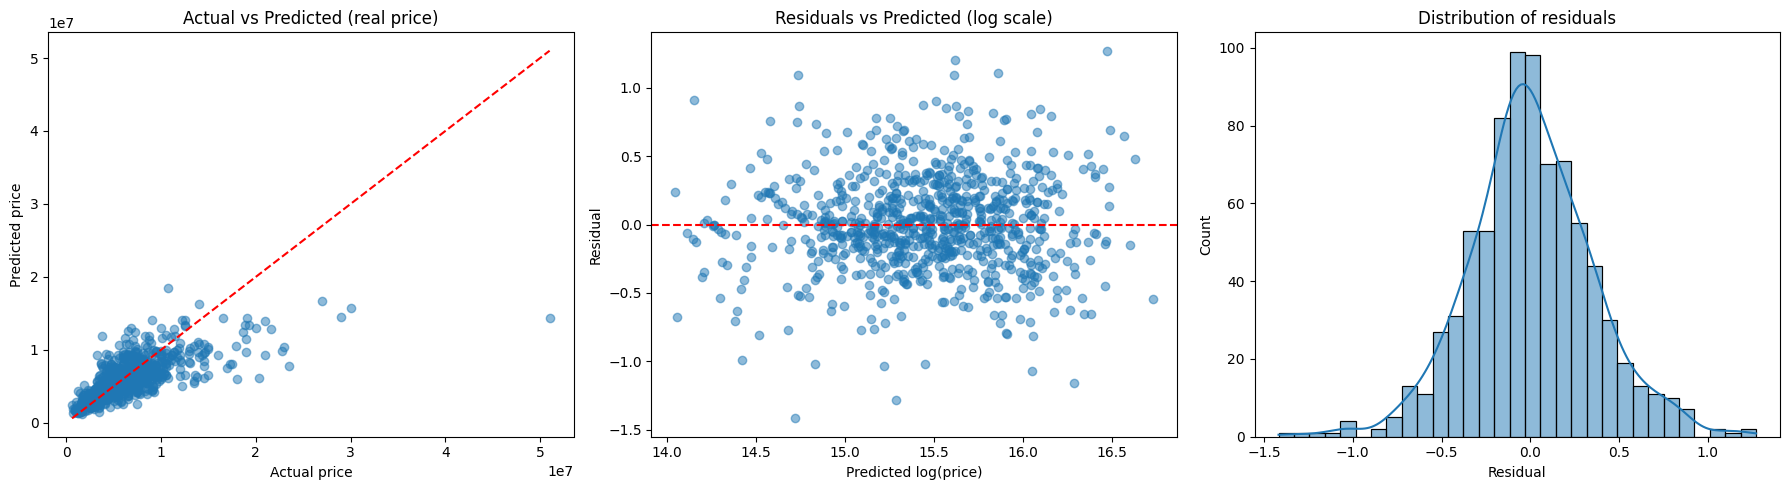

In [53]:
residuals = y_test - pred_log          # log scale
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_real, pred_real, alpha=0.5)
lim = [y_real.min(), y_real.max()]
axes[0].plot(lim, lim, 'r--')
axes[0].set_title('Actual vs Predicted (real price)')
axes[0].set_xlabel('Actual price'); axes[0].set_ylabel('Predicted price')

axes[1].scatter(pred_log, residuals, alpha=0.5)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_title('Residuals vs Predicted (log scale)')
axes[1].set_xlabel('Predicted log(price)'); axes[1].set_ylabel('Residual')

sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set_title('Distribution of residuals')
axes[2].set_xlabel('Residual')
plt.tight_layout()
plt.show()

In [54]:
errors_pct = np.abs(pred_real - y_real) / y_real * 100
print("=== Automatic interpretation of the results ===")
print(f"- Selected model: {best_name}.")
print(f"- R2 = {results.loc['R2', 'Real price (EGP)']:.3f} on the real price (and {results.loc['R2', 'log(price)']:.3f} on the log scale): "
      f"the model explains {results.loc['R2', 'Real price (EGP)']:.0%} of the variation of the price.")
print(f"- Typical error: MAE = {results.loc['MAE', 'Real price (EGP)']:,.0f} EGP; median error = {np.median(errors_pct):.1f}% of the real price; "
      f"RMSE = {results.loc['RMSE', 'Real price (EGP)']:,.0f} EGP (bigger because expensive apartments count more).")
print(f"- {np.mean(errors_pct < 10):.0%} of the apartments are predicted within 10% of the real price.")
print(f"- Mean residual (log) = {residuals.mean():.3f} (close to 0 means no systematic over/under prediction).")
print(f"- The top 3 models differ by only {tuning_df['After tuning (best_score_)'].max() - tuning_df['After tuning (best_score_)'].min():.3f} in CV R2.")

=== Automatic interpretation of the results ===
- Selected model: HistGradientBoosting.
- R2 = 0.510 on the real price (and 0.663 on the log scale): the model explains 51% of the variation of the price.
- Typical error: MAE = 1,726,507 EGP; median error = 20.8% of the real price; RMSE = 2,937,080 EGP (bigger because expensive apartments count more).
- 26% of the apartments are predicted within 10% of the real price.
- Mean residual (log) = 0.005 (close to 0 means no systematic over/under prediction).
- The top 3 models differ by only 0.026 in CV R2.


**Interpretation**
- **R² (real price)** tells how much of the price variation is explained; **MAE** is the average error in EGP; **RMSE / MSE** punish the big errors of expensive apartments more.
- **Actual vs Predicted:** points near the red diagonal are good predictions; expensive apartments are harder because there are few of them.
- **Residuals vs Predicted:** a random cloud around 0 is what we want; a curve or funnel would show a missing pattern or errors that grow with the price.
- **Histogram of residuals:** bell-shaped and centred on 0 means balanced errors.
- **Limits:** listings are asking prices (not final sale prices), the location (city / compound) is not in the data, and rows with impossible values were removed or set to missing during cleaning.

## 12. Conclusions
- The messy text columns were cleaned (units removed, shifted columns repaired, impossible values set to missing); the missing values are filled with the median of the train data only, scaling uses train data only.
- Training on `log(price)` and `log1p` of the skewed features make the models work well on this skewed data.
- The final model was chosen with cross-validation, tuned with `GridSearchCV`, and evaluated on the test set once.
- Possible improvements: add the location (city / compound), feature engineering (e.g. rooms per area), more tuning.

## 13. Gradio app

In [55]:
import gradio as gr


def predict_price(area, rooms, bathrooms, floor, year_built, seller, view, payment, finish):
    if None in (area, rooms, bathrooms, floor, year_built, seller, view, payment, finish):
        return " "

    row = pd.DataFrame([{
        "area_sqm": area, "rooms": rooms, "bathrooms": bathrooms, "floor_level": floor,
        "year_built": year_built, "seller_type": seller, "view": view,
        "payment_method": payment, "finishing_type": finishing[finish],
    }])


    row = pd.get_dummies(row, columns=onehot_cols)
    row = row.reindex(columns=X.columns, fill_value=0).astype(float)


    row[skewed] = np.log1p(row[skewed])
    row[num_cols] = scaler.transform(row[num_cols])

    price = np.expm1(best_model.predict(row))[0]
    return f"Estimated Price: {price:,.0f} EGP"


demo = gr.Interface(
    fn=predict_price,
    inputs=[
        gr.Number(label="Area (sqm)", value=150),
        gr.Dropdown(["1", "2", "3", "4", "5"], label="Rooms", value="3"),
        gr.Dropdown(["1", "2", "3", "4", "5"], label="Bathrooms", value="2"),
        gr.Number(label="Floor (0 = Ground)", value=3, precision=0),
        gr.Number(label="Year Built (or delivery year)", value=2025, precision=0),
        gr.Dropdown(sorted(df_clean["seller_type"].unique()), label="Seller Type", value="Broker"),
        gr.Dropdown(sorted(df_clean["view"].unique()), label="View", value="Main Street"),
        gr.Dropdown(sorted(df_clean["payment_method"].unique()), label="Payment Method", value="Cash"),
        gr.Dropdown(list(finishing.keys()), label="Finishing Type", value="Super Lux"),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Apartment Price Prediction App",
    description="Enter the apartment details to estimate its price.",
)

demo.launch(share=True)   # share=True gives a public link when you run it in Colab

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3920762bd55389ce07.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
